# Objective 1 · Measuring smartphone use from LSApp events

How much time did a participant spend in an app during a recorded session? LSApp logs individual events. This notebook reconstructs an **app episode** from an `Opened` event and its matching `Closed` event, measures the elapsed time, and places the episode alongside timestamped `User Interaction` events.

The workflow follows the Parry and Toth (2025) adaptation in `Research_Project_Objective_1.ipynb`. LSApp supplies the session identifiers. Its event log lacks the screen-state and lock/unlock signals needed to identify glances, so the measurements here cover sessions, episodes and interactions.

Run the cells from top to bottom in a Python 3 Jupyter kernel with pandas and Matplotlib. Start in the project folder or its `Notebooks` subfolder. The last step includes an optional Excel export using openpyxl.

## 1. Read the event log

The project stores the data in `Datasets/lsapp.tsv.gz`. Despite its filename, this is a compressed **tar archive** containing `lsapp.tsv`. Reading that member directly gives the five original fields and excludes a padding record that appeared as an empty row in the original notebook. If the data lives elsewhere, set `data_path` in the next cell to its location.

In [1]:
from pathlib import Path
import tarfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

project_dir = Path.cwd()
if project_dir.name.lower() == "notebooks":
    project_dir = project_dir.parent
data_path = project_dir / "Datasets" / "lsapp.tsv.gz"

session_key = ["user_id", "session_id"]
app_key = [*session_key, "app_name"]
episode_key = [*session_key, "episode_number"]

with tarfile.open(data_path, "r:gz") as archive:
    with archive.extractfile("lsapp.tsv") as tsv:
        telemetry_df = pd.read_csv(
            tsv, sep="\t", parse_dates=["timestamp"],
            dtype={"user_id": "Int32", "session_id": "Int32",
                   "app_name": "category", "event_type": "category"},
        )

# Alphabetical app order reproduces the tie-breaker used later in the event stream.
apps = telemetry_df["app_name"].cat.categories
telemetry_df["app_name"] = telemetry_df["app_name"].cat.reorder_categories(sorted(apps))
telemetry_df.index.name = "source_row"
print(f"{len(telemetry_df):,} logged events · {telemetry_df.shape[1]} fields")
display(telemetry_df.head(), telemetry_df.tail())

3,658,589 logged events · 5 fields


,user_id,session_id,timestamp,app_name,event_type
source_row,,,,,
0,0,1,2018-01-16 06:01:05,Minesweeper Classic (Mines),Opened
1,0,1,2018-01-16 06:01:05,Minesweeper Classic (Mines),Closed
2,0,1,2018-01-16 06:01:07,Minesweeper Classic (Mines),Opened
3,0,1,2018-01-16 06:01:07,Minesweeper Classic (Mines),Closed
4,0,1,2018-01-16 06:01:08,Minesweeper Classic (Mines),Opened


,user_id,session_id,timestamp,app_name,event_type
source_row,,,,,
3658584,291,76247,2018-04-06 14:35:15,Facebook,Closed
3658585,291,76247,2018-04-06 14:35:15,Facebook,Opened
3658586,291,76247,2018-04-06 14:35:37,Facebook,Closed
3658587,291,76247,2018-04-06 14:35:37,Facebook,Opened
3658588,291,76247,2018-04-06 14:35:52,Facebook Messenger,User Interaction


### Identify the fields and the observation window

One row records an event for one participant, app and supplied session. Distinct counts describe coverage. The earliest and latest timestamps give the span of the dataset as a whole. Individual participants can have shorter observation periods.

In [2]:
field_purpose = {
    "user_id": "Participant identifier",
    "session_id": "LSApp session identifier",
    "timestamp": "Recorded event time",
    "app_name": "Application involved",
    "event_type": "Logged action",
}
profile = pd.DataFrame({
    "meaning": field_purpose,
    "dtype": telemetry_df.dtypes.astype(str),
    "distinct_values": telemetry_df.nunique(),
    "missing_values": telemetry_df.isna().sum(),
})
display(profile)
first_event, last_event = telemetry_df["timestamp"].agg(["min", "max"])
print(f"First event: {first_event}  |  Last event: {last_event}")
print(f"Observation span: {last_event - first_event}")

,meaning,dtype,distinct_values,missing_values
user_id,Participant identifier,Int32,292,0
session_id,LSApp session identifier,Int32,76247,0
timestamp,Recorded event time,datetime64[ns],942582,0
app_name,Application involved,category,87,0
event_type,Logged action,category,4,0


First event: 2017-09-09 17:16:06  |  Last event: 2018-05-17 08:42:29
Observation span: 249 days 15:26:23


## 2. Describe activity before cleaning

Start with the original event frequencies. A high count of opens or closes can reflect repeated logging as well as use. These are counts of records. Step 4 determines which records can support an episode duration.

,events,percent
event_type,,
Opened,1673261,45.74
Closed,1667014,45.56
User Interaction,313829,8.58
Broken,4485,0.12


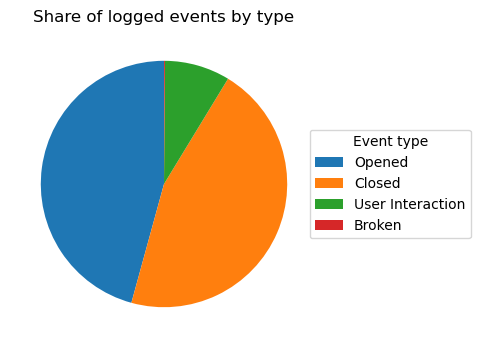

In [3]:
event_counts = telemetry_df["event_type"].value_counts()
display(pd.DataFrame({
    "events": event_counts,
    "percent": (100 * event_counts / event_counts.sum()).round(2),
}))

fig, ax = plt.subplots(figsize=(7, 4))
wedges, *_ = ax.pie(event_counts, startangle=90)
ax.legend(wedges, event_counts.index, title="Event type", loc="center left",
          bbox_to_anchor=(0.95, 0.5))
ax.set_title("Share of logged events by type")
plt.show()

### Compare participation, session activity and app reach

Count events, distinct sessions and distinct apps for each participant. For each user–session pair, measure the span from its first to its last recorded event. Then rank apps by event count and show how many participants contributed to each count.

In [4]:
participant_activity = telemetry_df.groupby("user_id").agg(
    events=("timestamp", "size"),
    sessions=("session_id", "nunique"),
    apps=("app_name", "nunique"),
)
raw_sessions = telemetry_df.groupby(session_key).agg(
    first_event=("timestamp", "min"), last_event=("timestamp", "max"),
    events=("event_type", "size"), apps=("app_name", "nunique"),
)
raw_sessions["span_seconds"] = (
    raw_sessions["last_event"] - raw_sessions["first_event"]
).dt.total_seconds()

app_activity = (
    telemetry_df.groupby("app_name", observed=True)
    .agg(events=("event_type", "size"), participants=("user_id", "nunique"))
    .sort_values("events", ascending=False)
)
print("Activity per participant")
display(participant_activity.describe().round(2))
print("Activity per raw session")
display(raw_sessions[["events", "apps", "span_seconds"]].describe().round(2))
print("Top 15 apps by logged events")
display(app_activity.head(15))

Activity per participant


,events,sessions,apps
count,292.00,292.00,292.00
mean,12529.41,261.12,16.11
std,25094.13,484.98,6.48
min,2.00,1.00,1.00
25%,767.75,45.75,12.00
50%,3220.50,95.50,17.00
75%,10055.50,289.00,20.25
max,156245.00,5153.00,32.00


Activity per raw session


,events,apps,span_seconds
count,76247.00,76247.00,76247.00
mean,47.98,2.38,319.34
std,178.39,1.66,544.85
min,1.00,1.00,0.00
25%,4.00,1.00,9.00
50%,12.00,2.00,118.00
75%,36.00,3.00,400.00
max,17424.00,17.00,15280.00


Top 15 apps by logged events


,events,participants
app_name,,
Facebook,506209,179
Google Chrome,321183,266
Facebook Messenger,237622,177
Google,210108,237
Twitter,186339,67
Messages,157280,134
Instagram,126008,121
Reddit,123069,40
Gmail,107305,225


### Locate activity in time

For each hour and weekday, count events and the distinct sessions with activity in that period. A session spanning two hours contributes to both hourly counts. Weekday and hour come directly from the recorded timestamp.

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
events,185201,172653,160803,144461,118224,107207,97847,93369,79155,65469,...,172476,184984,185997,204661,194101,197329,214293,209758,192753,187238
active_sessions,4174,3942,3646,3264,2853,2448,1989,1807,1682,1730,...,3927,4174,4490,4482,4571,4544,4523,4479,4314,4074


weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
events,534588,602383,584764,522920,455037,449705,509192
active_sessions,11556,11310,11086,10697,10398,10815,10733


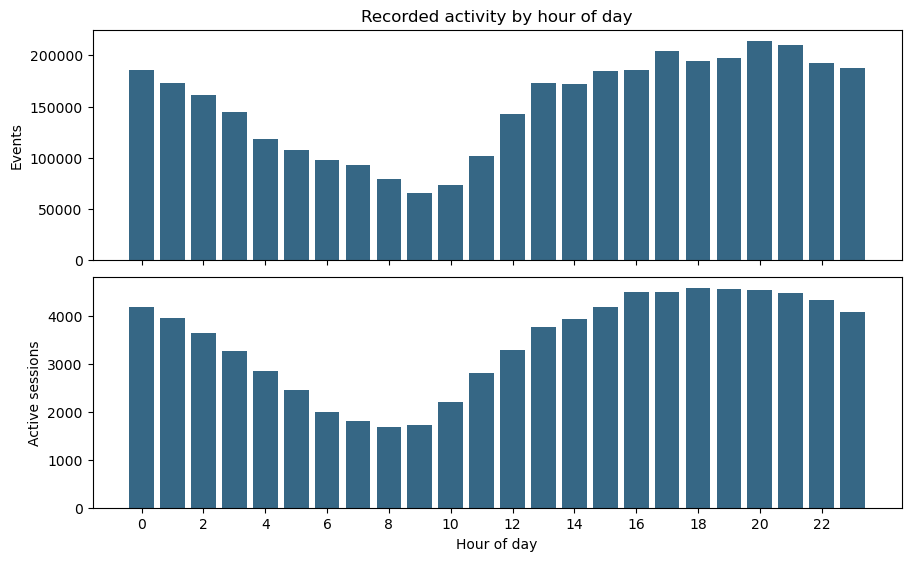

In [5]:
def activity_by_period(period):
    grouped = telemetry_df.groupby(period)["session_id"]
    return grouped.agg(events="size", active_sessions="nunique")

hourly = activity_by_period(telemetry_df["timestamp"].dt.hour).rename_axis("hour")
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = activity_by_period(telemetry_df["timestamp"].dt.day_name()).reindex(weekdays)
display(hourly.T, daily.rename_axis("weekday").T)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 5.5), layout="constrained")
for ax, column, label in zip(axes, ["events", "active_sessions"], ["Events", "Active sessions"]):
    ax.bar(hourly.index, hourly[column], color="#366785")
    ax.set_ylabel(label)
axes[0].set_title("Recorded activity by hour of day")
axes[1].set(xlabel="Hour of day", xticks=range(0, 24, 2))
plt.show()

### Check duplicates, timing and open/close structure

Check ordering in the recorded file before sorting. Then inspect elapsed seconds between consecutive events within each session. Events with a shared timestamp may belong to different apps, or they may be an open and a close for the same app. This distinction matters when removing duplicates.

In [6]:
duplicate_rows = telemetry_df.duplicated()
backwards_in_file = telemetry_df.groupby("user_id")["timestamp"].diff().lt(pd.Timedelta(0))
out_of_order_users = telemetry_df.loc[backwards_in_file, "user_id"].unique()
print(f"Duplicate raw rows beyond the first: {duplicate_rows.sum():,} ({duplicate_rows.mean():.2%})")
print(f"Participants with backwards timestamps in file order: {len(out_of_order_users)}")
print(f"Rows reusing an earlier timestamp anywhere in the log: {telemetry_df['timestamp'].duplicated().mean():.2%}")

# Keep the file position as the index so ties can be traced back to the raw log.
ordered = telemetry_df.sort_values([*session_key, "timestamp"], kind="stable")
gaps = ordered.groupby(session_key)["timestamp"].diff().dt.total_seconds()
events_at_time = ordered.groupby([*session_key, "timestamp"]).size()
display(gaps.describe(percentiles=[.25, .5, .75, .90, .95, .99]).rename("within_session_gap_seconds"),
        events_at_time.describe().rename("events_per_session_timestamp"))

Duplicate raw rows beyond the first: 2,185,366 (59.73%)
Participants with backwards timestamps in file order: 0


Rows reusing an earlier timestamp anywhere in the log: 74.24%


count    3.582342e+06
mean     6.796916e+00
std      2.790385e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
90%      9.000000e+00
95%      3.500000e+01
99%      1.630000e+02
max      3.000000e+02
Name: within_session_gap_seconds, dtype: float64

count    1.039489e+06
mean     3.519603e+00
std      4.741665e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      4.000000e+00
max      2.480000e+02
Name: events_per_session_timestamp, dtype: float64

In [7]:
# The same app can open several times in one session. Count each type before pairing.
app_session_types = (
    telemetry_df.groupby([*app_key, "event_type"], observed=True)
    .size().unstack("event_type", fill_value=0)
)
display(app_session_types.head(10))
display(app_session_types.sum(axis=1).describe().rename("events_per_app_session"),
        app_session_types.loc[app_session_types["Opened"] > 0, "Opened"]
        .describe().rename("opens_per_app_session_with_an_open"))

event_type                                      Broken  Closed  Opened  \
user_id session_id app_name                                              
0       1          Minesweeper Classic (Mines)       0      40      40   
        2          Gmail                             0       0       0   
                   Google                            0       2       2   
                   Google Chrome                     0       0       1   
                   Instagram                         0       1       1   
        3          Google Chrome                     0       2       1   
        4          Google Chrome                     0       2       2   
                   Minesweeper Classic (Mines)       0      42      42   
        5          Google Chrome                     0       2       2   
                   Minesweeper Classic (Mines)       0      50      50   

event_type                                      User Interaction  
user_id session_id app_name                                       
0       1          Minesweeper Classic (Mines)                 0  
        2          Gmail                                       1  
                   Google                                      0  
                   Google Chrome                               0  
                   Instagram                                   0  
        3          Google Chrome                               0  
        4          Google Chrome                               0  
                   Minesweeper Classic (Mines)                 0  
        5          Google Chrome                               0  
                   Minesweeper Classic (Mines)                 0

count    181837.000000
mean         20.120157
std          95.673103
min           1.000000
25%           2.000000
50%           6.000000
75%          16.000000
max       17064.000000
Name: events_per_app_session, dtype: float64

count    135270.000000
mean         12.369786
std          54.749127
min           1.000000
25%           2.000000
50%           4.000000
75%          10.000000
max        8532.000000
Name: opens_per_app_session_with_an_open, dtype: float64

## 3. Select the events used for measurement

The adaptation uses three LSApp labels. `Opened` and `Closed` provide interval boundaries. `User Interaction` provides a timestamped observation to add back later. Remove `Broken` records and missing event labels, then show how many records remain in each class.

In [8]:
event_classes = {
    "Opened": "episode_start",
    "Closed": "episode_stop",
    "User Interaction": "interaction",
}
pre_df = ordered.loc[
    ordered["event_type"].notna() & ordered["event_type"].ne("Broken")
].copy()
pre_df["event_class"] = pre_df["event_type"].map(event_classes)
assert pre_df["event_class"].notna().all(), "A retained event type needs a classification."
assert pre_df[[*app_key, "timestamp"]].notna().all().all(), "A retained event lacks a key or time."

print(f"Broken events: {ordered['event_type'].eq('Broken').sum():,}")
print(f"Missing event labels: {ordered['event_type'].isna().sum():,}")
print(f"Retained events: {len(pre_df):,}")
display(pre_df.groupby(["event_type", "event_class"], observed=True).size().rename("events"))

Broken events: 4,485
Missing event labels: 0
Retained events: 3,654,104


event_type        event_class  
Closed            episode_stop     1667014
Opened            episode_start    1673261
User Interaction  interaction       313829
Name: events, dtype: int64

## 4. Reconstruct application episodes

### Consolidate repeated boundaries

An exact boundary duplicate has the same participant, session, app, timestamp **and event type**. Keep the first occurrence. An open and a close for the same app at the same time are distinct observations. Keep both in source order, since reversing them can change which episode closes. Interaction rows bypass this step.

In [9]:
boundary_fields = [*app_key, "timestamp", "event_type"]
boundaries = pre_df.loc[pre_df["event_type"].isin(["Opened", "Closed"]), boundary_fields]
before = boundaries["event_type"].value_counts()
duplicate_boundaries = boundaries.duplicated(boundary_fields, keep="first")
print(f"Rows in duplicate boundary groups: {boundaries.duplicated(boundary_fields, keep=False).sum():,}")
display(boundaries.loc[boundaries.duplicated(boundary_fields, keep=False)].head(6))

boundaries = boundaries.loc[~duplicate_boundaries].sort_values(
    [*session_key, "timestamp", "app_name", "source_row"]
)
after = boundaries["event_type"].value_counts()
boundary_counts = pd.DataFrame({"before": before, "retained": after, "removed": before - after})
display(boundary_counts.loc[["Opened", "Closed"]])
assert not boundaries.duplicated(boundary_fields).any()

# After deduplication, two boundaries at one app timestamp imply one open and one close.
tie_key = [*app_key, "timestamp"]
same_time = boundaries.duplicated(tie_key, keep=False)
print(f"App timestamps containing both boundaries: {boundaries.loc[same_time, tie_key].drop_duplicates().shape[0]:,}")
display(boundaries.loc[same_time].head(8))

Rows in duplicate boundary groups: 2,624,821


,user_id,session_id,app_name,timestamp,event_type
source_row,,,,,
4,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,Opened
5,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,Closed
6,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,Opened
7,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,Closed
16,0,1,Minesweeper Classic (Mines),2018-01-16 06:03:49,Opened
17,0,1,Minesweeper Classic (Mines),2018-01-16 06:03:49,Closed


,before,retained,removed
event_type,,,
Opened,1673261,652859,1020402
Closed,1667014,674423,992591


App timestamps containing both boundaries: 340,433


,user_id,session_id,app_name,timestamp,event_type
source_row,,,,,
0,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,Opened
1,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,Closed
2,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:07,Opened
3,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:07,Closed
4,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,Opened
5,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,Closed
8,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:09,Opened
9,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:09,Closed


### Pair each close with the first open still waiting

Follow the ordered boundaries, tracking one pending open for each `(user_id, session_id, app_name)`. A close completes that app’s pending episode. A second open while one is pending is logged as `repeated_open` and the earlier open stays active. A close with no pending open is an `unmatched_close`. Any open still pending at the end is an `unmatched_open`.

The pairing function returns the source rows for each completed pair and each anomaly. Those row numbers let us trace a duration or inspect a rejected boundary.

In [10]:
def pair_boundaries(ordered_boundaries):
    """Return completed source-row pairs and anomalies for independent app streams."""
    pending = {}
    pairs = []
    anomalies = []
    for row_id, user, session, app, event in ordered_boundaries[
        [*app_key, "event_type"]
    ].itertuples(name=None):
        key = (user, session, app)
        if event == "Opened":
            if key in pending:
                anomalies.append((row_id, "repeated_open"))
            else:
                pending[key] = row_id
        else:  # Only Closed boundaries reach this branch.
            open_id = pending.pop(key, None)
            if open_id is None:
                anomalies.append((row_id, "unmatched_close"))
            else:
                pairs.append((open_id, row_id))

    anomalies.extend((row_id, "unmatched_open") for row_id in pending.values())
    return (pd.DataFrame(pairs, columns=["open_row", "close_row"]),
            pd.DataFrame(anomalies, columns=["source_row", "anomaly_type"]))

In [11]:
pairs, anomaly_rows = pair_boundaries(boundaries)
starts = telemetry_df.loc[pairs["open_row"], [*app_key, "timestamp"]].reset_index(drop=True)
stops = telemetry_df.loc[pairs["close_row"], [*app_key, "timestamp"]].reset_index(drop=True)
assert starts[app_key].equals(stops[app_key]), "Episode endpoints belong to different app streams."

episodes_df = starts.rename(columns={"timestamp": "start_time"}).assign(
    end_time=stops["timestamp"], open_row=pairs["open_row"], close_row=pairs["close_row"],
)
episodes_df["duration_seconds"] = (episodes_df["end_time"] - episodes_df["start_time"]).dt.total_seconds()
anomalies_df = anomaly_rows.join(telemetry_df, on="source_row", validate="many_to_one")
# Every retained boundary contributes to exactly one pair or one anomaly.
assert 2 * len(episodes_df) + len(anomalies_df) == len(boundaries)
print(f"Completed episodes: {len(episodes_df):,}  |  Unpaired boundaries: {len(anomalies_df):,}")
display(anomalies_df["anomaly_type"].value_counts().rename("boundaries"))
display(anomalies_df.groupby("anomaly_type", sort=False).head(2))
display(episodes_df.head())

Completed episodes: 585,520  |  Unpaired boundaries: 156,242


anomaly_type
unmatched_close    88903
repeated_open      47850
unmatched_open     19489
Name: boundaries, dtype: int64

,source_row,anomaly_type,user_id,session_id,timestamp,app_name,event_type
0,88,unmatched_close,0,3,2018-01-16 06:34:35,Google Chrome,Closed
1,342,unmatched_close,0,6,2018-01-16 08:33:36,Minesweeper Classic (Mines),Closed
2,345,repeated_open,0,6,2018-01-16 08:33:37,Minesweeper Classic (Mines),Opened
4,564,repeated_open,0,10,2018-01-16 11:03:17,Minesweeper Classic (Mines),Opened
136753,87,unmatched_open,0,2,2018-01-16 06:26:26,Google Chrome,Opened
136754,1018,unmatched_open,0,31,2018-01-16 22:43:56,Google Chrome,Opened


,user_id,session_id,app_name,start_time,end_time,open_row,close_row,duration_seconds
0,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,2018-01-16 06:01:05,0,1,0.0
1,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:07,2018-01-16 06:01:07,2,3,0.0
2,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:08,2018-01-16 06:01:08,4,5,0.0
3,0,1,Minesweeper Classic (Mines),2018-01-16 06:01:09,2018-01-16 06:01:09,8,9,0.0
4,0,1,Minesweeper Classic (Mines),2018-01-16 06:03:44,2018-01-16 06:03:44,10,11,0.0


## 5. Validate the supplied sessions

Build a reference table from **all retained events**, including sessions with interactions only. Each session is identified by both participant and session ID. Its observed span runs from the first retained event to the last.

The five-minute check asks whether an `Opened` event follows another retained event in the **same session** by more than 300 seconds. Compute gaps within the supplied boundaries so the first event of each session has no preceding gap.

In [12]:
session_reference = pre_df.groupby(session_key).agg(
    session_start=("timestamp", "min"), session_end=("timestamp", "max"),
    event_count=("timestamp", "size"), unique_apps=("app_name", "nunique"),
)
session_reference["span_seconds"] = (
    session_reference["session_end"] - session_reference["session_start"]
).dt.total_seconds()
within_gap = pre_df.groupby(session_key)["timestamp"].diff().dt.total_seconds()
late_opens = pre_df["event_type"].eq("Opened") & within_gap.gt(300)
users_per_id = pre_df.groupby("session_id")["user_id"].nunique()
print(f"Sessions in the raw log: {len(raw_sessions):,}  |  Sessions with retained events: {len(session_reference):,}")
display(session_reference[["event_count", "unique_apps", "span_seconds"]]
        .describe(percentiles=[.5, .75, .9, .95, .99]).round(2))
display(pd.Series({
    "Session IDs shared by multiple users": users_per_id.gt(1).sum(),
    "Missing session start or end": session_reference[["session_start", "session_end"]].isna().any(axis=1).sum(),
    "Negative session spans": session_reference["span_seconds"].lt(0).sum(),
    "Opened after a within-session gap over 300 s": late_opens.sum(),
}, name="count"))
if late_opens.any():
    display(pre_df.loc[late_opens, ["user_id", "session_id", "timestamp", "app_name"]]
            .assign(gap_seconds=within_gap[late_opens]).nlargest(10, "gap_seconds"))

Sessions in the raw log: 76,247  |  Sessions with retained events: 76,245


,event_count,unique_apps,span_seconds
count,76245.00,76245.00,76245.00
mean,47.93,2.38,319.33
std,178.30,1.66,544.85
min,1.00,1.00,0.00
50%,12.00,2.00,118.00
75%,36.00,3.00,400.00
90%,102.00,5.00,867.00
95%,189.00,6.00,1295.80
99%,566.56,8.00,2525.00
max,17424.00,17.00,15280.00


Session IDs shared by multiple users            0
Missing session start or end                    0
Negative session spans                          0
Opened after a within-session gap over 300 s    0
Name: count, dtype: int64

## 6. Number, clean and validate the episodes

Sort episodes within each session by start time, then end time and app name to resolve ties. Number from one in every session. The three columns `(user_id, session_id, episode_number)` identify an episode across the dataset.

Apply the original cleansing rule before aggregation. Exclude episodes with missing identifiers, times or duration, or with negative duration. Keep a pair whose two events have the same recorded second. Its observed duration is zero and it still counts as an episode.

In [13]:
episodes_df = episodes_df.sort_values([*session_key, "start_time", "end_time", "app_name"]).reset_index(drop=True)
episodes_df["episode_number"] = episodes_df.groupby(session_key).cumcount() + 1
episode_fields = [*episode_key, "app_name", "start_time", "end_time", "duration_seconds"]
episode_data = episodes_df[episode_fields]
invalid = episode_data[episode_fields].isna().any(axis=1) | episode_data["duration_seconds"].lt(0)
episode_data_final = episode_data.loc[~invalid].reset_index(drop=True)

zero_duration = episode_data_final["duration_seconds"].eq(0)
print(f"Episodes before cleansing: {len(episode_data):,}  |  Removed: {invalid.sum():,}")
print(f"Zero-duration episodes retained: {zero_duration.sum():,} ({zero_duration.mean():.2%})")
display(episode_data_final.loc[zero_duration].head(3))

Episodes before cleansing: 585,520  |  Removed: 0
Zero-duration episodes retained: 55,073 (9.41%)


,user_id,session_id,episode_number,app_name,start_time,end_time,duration_seconds
0,0,1,1,Minesweeper Classic (Mines),2018-01-16 06:01:05,2018-01-16 06:01:05,0.0
1,0,1,2,Minesweeper Classic (Mines),2018-01-16 06:01:07,2018-01-16 06:01:07,0.0
2,0,1,3,Minesweeper Classic (Mines),2018-01-16 06:01:08,2018-01-16 06:01:08,0.0


### Check session membership and chronological order

Compare both ends of each episode with the first and last event in its supplied session. Check that numbering restarts at one and progresses without gaps, and that one episode of an app has finished before the next starts. Episodes for different apps can overlap.

In [14]:
with_session = episode_data_final.join(
    session_reference[["session_start", "session_end"]], on=session_key, validate="many_to_one"
)
expected_number = episode_data_final.groupby(session_key).cumcount() + 1
start_gap = episode_data_final.groupby(session_key)["start_time"].diff()
previous_end = episode_data_final.groupby(app_key, observed=True)["end_time"].shift()
episode_checks = pd.Series({
    "Episodes without a reference session": with_session["session_start"].isna().sum(),
    "Episodes outside their session span": (
        with_session["start_time"].lt(with_session["session_start"])
        | with_session["end_time"].gt(with_session["session_end"])
    ).sum(),
    "Reused opening or closing rows": pairs["open_row"].duplicated().sum() + pairs["close_row"].duplicated().sum(),
    "Duplicate episode identifiers": episode_data_final.duplicated(episode_key).sum(),
    "Episode numbers out of sequence": episode_data_final["episode_number"].ne(expected_number).sum(),
    "Episodes starting before the previous start": start_gap.lt(pd.Timedelta(0)).sum(),
    "Overlaps within the same app and session": episode_data_final["start_time"].lt(previous_end).sum(),
}, name="violations")
display(episode_checks)
assert episode_checks.eq(0).all(), "Inspect the episode checks before aggregating."

Episodes without a reference session           0
Episodes outside their session span            0
Reused opening or closing rows                 0
Duplicate episode identifiers                  0
Episode numbers out of sequence                0
Episodes starting before the previous start    0
Overlaps within the same app and session       0
Name: violations, dtype: int64

## 7. Measure app use within sessions

Summarise the distribution of episode durations in seconds and minutes. Then aggregate the same episodes twice. The **session–app** table answers how often and for how long a particular app was used in a session. The **session** table combines all apps and counts distinct apps with a completed episode.

The duration total adds up measured app intervals. The session span in Step 5 measures elapsed time between observed events and can include gaps. Only sessions with at least one completed episode enter the tables below.

In [15]:
durations = episode_data_final["duration_seconds"]
duration_summary = pd.DataFrame({"seconds": durations, "minutes": durations / 60}).describe(
    percentiles=[.5, .75, .9, .95, .99, .999]
)
display(duration_summary.round(3))

,seconds,minutes
count,585520.000,585520.000
mean,24.186,0.403
std,50.048,0.834
min,0.000,0.000
50%,5.000,0.083
75%,22.000,0.367
90%,68.000,1.133
95%,122.000,2.033
99%,250.000,4.167
99.9%,392.000,6.533


In [16]:
session_app_metrics = episode_data_final.groupby(app_key, observed=True).agg(
    episode_count=("episode_number", "size"),
    total_duration_seconds=("duration_seconds", "sum"),
    mean_episode_duration_seconds=("duration_seconds", "mean"),
    max_episode_duration_seconds=("duration_seconds", "max"),
).reset_index()
session_episode_metrics = episode_data_final.groupby(session_key).agg(
    episode_count=("episode_number", "size"),
    total_episode_duration_seconds=("duration_seconds", "sum"),
    mean_episode_duration_seconds=("duration_seconds", "mean"),
    max_episode_duration_seconds=("duration_seconds", "max"),
    unique_apps=("app_name", "nunique"),
).reset_index()

# Both ways of grouping must account for every measured episode.
assert session_app_metrics["episode_count"].sum() == session_episode_metrics["episode_count"].sum() == len(durations)
assert session_app_metrics["total_duration_seconds"].sum() == session_episode_metrics["total_episode_duration_seconds"].sum() == durations.sum()
print(f"Session–app combinations: {len(session_app_metrics):,}")
display(session_app_metrics.head())
print(f"Sessions with completed episodes: {len(session_episode_metrics):,}")
display(session_episode_metrics.head())

Session–app combinations: 128,855


,user_id,session_id,app_name,episode_count,total_duration_seconds,mean_episode_duration_seconds,max_episode_duration_seconds
0,0,1,Minesweeper Classic (Mines),31,0.0,0.0,0.0
1,0,2,Google,2,10.0,5.0,5.0
2,0,2,Instagram,1,11.0,11.0,11.0
3,0,3,Google Chrome,1,51.0,51.0,51.0
4,0,4,Google Chrome,2,0.0,0.0,0.0


Sessions with completed episodes: 58,697


,user_id,session_id,episode_count,total_episode_duration_seconds,mean_episode_duration_seconds,max_episode_duration_seconds,unique_apps
0,0,1,31,0.0,0.000000,0.0,1
1,0,2,3,21.0,7.000000,11.0,2
2,0,3,1,51.0,51.000000,51.0,1
3,0,4,36,1.0,0.027778,1.0,2
4,0,5,39,0.0,0.000000,0.0,2


## 8. Assemble the chronological session event stream

Place each episode at its start time and restore every retained `User Interaction` at its recorded timestamp. An interaction has no measured interval, so its episode number, start, end and duration stay empty. A zero in an episode’s duration and an empty value in an interaction’s duration have different meanings.

Sort by participant, session, timestamp and app name. For an exact tie between the two classes, the episode row comes first, matching the original concatenation order. Assign `session_event_number` to **every** row. The separate `episode_number` identifies only completed intervals.

In [17]:
stream_fields = [
    *episode_key, "app_name", "timestamp", "event_class",
    "start_time", "end_time", "duration_seconds",
]
episode_events = episode_data_final.assign(
    timestamp=episode_data_final["start_time"], event_class="episode"
)
interaction_events = pre_df.loc[
    pre_df["event_class"].eq("interaction"), [*app_key, "timestamp"]
].copy()
interaction_events = interaction_events.assign(
    episode_number=pd.array([pd.NA] * len(interaction_events), dtype="Int64"),
    event_class="interaction", start_time=pd.NaT, end_time=pd.NaT,
    duration_seconds=float("nan"),
)

session_event_stream_final = (
    pd.concat([episode_events[stream_fields], interaction_events[stream_fields]], ignore_index=True)
    .sort_values([*session_key, "timestamp", "app_name"], kind="stable", ignore_index=True)
)
session_event_stream_final["session_event_number"] = (
    session_event_stream_final.groupby(session_key).cumcount() + 1
)

### Reconcile the stream and inspect one session

Check that every episode and interaction appears once, the timestamps are in order, and every record belongs to a known session. Finally, read participant 0’s session 28 in sequence. Its first Google episode spans two interactions, so the entries illustrate how interval and point observations coexist.

In [18]:
stream = session_event_stream_final
is_episode = stream["event_class"].eq("episode")
is_interaction = stream["event_class"].eq("interaction")
point_fields = ["episode_number", "start_time", "end_time", "duration_seconds"]
stream_sessions = pd.MultiIndex.from_frame(stream[session_key].drop_duplicates())
stream_gaps = stream.groupby(session_key)["timestamp"].diff()

stream_checks = pd.Series({
    "Missing user, session or timestamp": stream[[*session_key, "timestamp"]].isna().any(axis=1).sum(),
    "Unknown sessions": len(stream_sessions.difference(session_reference.index)),
    "Backwards timestamps within a session": stream_gaps.lt(pd.Timedelta(0)).sum(),
    "Duplicate episode identifiers": stream.loc[is_episode].duplicated(episode_key).sum(),
    "Interactions carrying episode fields": stream.loc[is_interaction, point_fields].notna().any(axis=1).sum(),
}, name="violations")
display(stream_checks)
assert stream_checks.eq(0).all(), "Inspect the session event stream checks."
assert is_episode.sum() == len(episode_data_final)
assert is_interaction.sum() == pre_df["event_type"].eq("User Interaction").sum()
assert len(stream) == is_episode.sum() + is_interaction.sum()
display(stream["event_class"].value_counts().rename("records").to_frame())
print(f"Final stream: {len(stream):,} records across {len(stream_sessions):,} sessions")
display(stream.loc[stream["user_id"].eq(0) & stream["session_id"].eq(28)])

Missing user, session or timestamp       0
Unknown sessions                         0
Backwards timestamps within a session    0
Duplicate episode identifiers            0
Interactions carrying episode fields     0
Name: violations, dtype: int64

,records
event_class,
episode,585520
interaction,313829


Final stream: 899,349 records across 70,979 sessions


,user_id,session_id,episode_number,app_name,timestamp,event_class,start_time,end_time,duration_seconds,session_event_number
368,0,28,1,Google,2018-01-16 21:47:58,episode,2018-01-16 21:47:58,2018-01-16 21:48:09,11.0,1
369,0,28,<NA>,YouTube,2018-01-16 21:48:02,interaction,NaT,NaT,NaN,2
370,0,28,<NA>,Maps,2018-01-16 21:48:06,interaction,NaT,NaT,NaN,3
371,0,28,2,Google,2018-01-16 21:48:39,episode,2018-01-16 21:48:39,2018-01-16 21:48:43,4.0,4


## 9. Use or export the results

| Table | What one row represents |
| --- | --- |
| `episode_data_final` | One completed app episode, with its observed start, end and duration |
| `session_app_metrics` | Episode counts and duration measures for one app in one session |
| `session_episode_metrics` | Episode counts, duration measures and app diversity for one session |
| `session_event_stream_final` | One episode or interaction in chronological order within a session |
| `anomalies_df` | One unpaired boundary, its source row and the reason it was flagged |

Set `export_excel` to `True` below to save the ten-column event stream to `Datasets/lsapp_objective1_step_by_step.xlsx`. The writer streams rows to keep memory use manageable. Missing episode fields become blank Excel cells.

In [19]:
export_excel = False

if export_excel:
    from openpyxl import Workbook

    output_path = data_path.with_name("lsapp_objective1_step_by_step.xlsx")
    workbook = Workbook(write_only=True)
    sheet = workbook.create_sheet("Session events")
    sheet.append(session_event_stream_final.columns.tolist())
    for row in session_event_stream_final.itertuples(index=False, name=None):
        sheet.append([None if pd.isna(value) else value for value in row])
    workbook.save(output_path)
    print(f"Saved {len(session_event_stream_final):,} records to {output_path}")